# 06 · Regresión espacial y Machine Learning a escala

**Parte A. Explicar:** ¿qué factores geográficos se asocian a la perturbación?
Se agregan los hexágonos a resolución 8 (~0.74 km²) y se comparan MCO, el modelo de rezago
espacial (SLM) y el de error espacial (SEM), elegidos con los tests de multiplicadores de Lagrange.

**Parte B. Predecir:** clasificar a nivel de píxel (millones de filas) qué bosque se perdió.
Patrón *entrenar en pequeño, puntuar en grande*: se entrena con una muestra estratificada y el
modelo se distribuye a los workers con `mapInPandas` para puntuar todos los píxeles.
Se evalúa con **validación cruzada por bloques espaciales**, porque la autocorrelación espacial
infla las métricas de una validación aleatoria.

In [0]:
%pip install -q rasterio pyproj h3 geopandas shapely esda libpysal spreg pykrige scikit-gstat mapclassify scikit-learn mlflow
dbutils.library.restartPython()

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
import sys, os, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

# Raíz del repositorio (Git folder en Databricks o clon local)
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "src"))

from geocloud import config as C, dbx
spark = dbx.get_spark()
VOL = dbx.volume_path()
FIG = Path(VOL) / "figures"
FIG.mkdir(parents=True, exist_ok=True)
print("Databricks:", dbx.is_databricks(), "| Volume:", VOL)

Databricks: True | Volume: /Volumes/workspace/madre_dios_rs/raw


In [0]:
import numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
from geocloud import spatial

feat = spark.table(dbx.tbl("gold_h3_features")).toPandas().pipe(dbx.clean)
YEARS = sorted(int(c.split("_")[1]) for c in feat.columns if c.startswith("ndvi_") and c.split("_")[1].isdigit())
Y0, Y1 = YEARS[0], YEARS[-1]
gdf = spatial.h3_to_geodataframe(feat, crs_out=C.CRS_UTM)
print(f"Hexágonos: {len(gdf):,} | años: {YEARS}")

Hexágonos: 21,854 | años: [2018, 2020, 2022, 2024, 2025]


## Parte A. Regresión espacial

In [0]:
import h3, spreg
covs = [c for c in ["dist_via_km", "dist_rio_km", "en_anp", "en_za", "treecover2000"] if c in feat]
df = feat.dropna(subset=["d_pert"] + covs).copy()
df["h3_8"] = df.h3.map(lambda c: h3.cell_to_parent(c, C.H3_RES_COARSE))
agg = df.groupby("h3_8").agg(d_pert=("d_pert", "mean"), n=("h3", "size"),
                             **{c: (c, "mean") for c in covs}).reset_index()
agg = agg[agg.n >= 4].reset_index(drop=True)

X = pd.DataFrame(index=agg.index)
if "dist_via_km" in agg: X["log_dist_via"] = np.log1p(agg.dist_via_km)
if "dist_rio_km" in agg: X["log_dist_rio"] = np.log1p(agg.dist_rio_km)
if "en_anp" in agg and agg.en_anp.std() > 0: X["frac_anp"] = agg.en_anp
if "en_za" in agg and agg.en_za.std() > 0: X["frac_zona_amort"] = agg.en_za
if "treecover2000" in agg: X["cobertura_2000"] = agg.treecover2000 / 100
X = X.loc[:, X.std() > 1e-6]          # descarta covariables constantes (colinealidad con el intercepto)
y = agg[["d_pert"]].values

w8 = spatial.h3_weights(agg.h3_8, k=1)
if w8.islands:
    keep = ~agg.h3_8.isin(w8.islands)
    agg, X, y = agg[keep].reset_index(drop=True), X[keep].reset_index(drop=True), y[keep.values]
    w8 = spatial.h3_weights(agg.h3_8, k=1)
print(f"Unidades de análisis (H3 res 8): {w8.n:,}")

Unidades de análisis (H3 res 8): 3,124


In [0]:
ols = spreg.OLS(y, X.values, w=w8, spat_diag=True, moran=True, name_y="d_pert", name_x=list(X.columns))
diag = pd.DataFrame({
    "estadístico": ["I de Moran (residuos)", "LM rezago", "LM error", "LM rezago robusto", "LM error robusto"],
    "valor": [ols.moran_res[0], ols.lm_lag[0], ols.lm_error[0], ols.rlm_lag[0], ols.rlm_error[0]],
    "p": [ols.moran_res[2], ols.lm_lag[1], ols.lm_error[1], ols.rlm_lag[1], ols.rlm_error[1]]})
print(f"MCO R² = {ols.r2:.3f}"); diag.round(4)

MCO R² = 0.039


,estadístico,valor,p
0,I de Moran (residuos),0.5923,0.0000
1,LM rezago,3170.1535,0.0000
2,LM error,3171.3582,0.0000
3,LM rezago robusto,2.4662,0.1163
4,LM error robusto,3.6710,0.0554


In [0]:
lag = spreg.ML_Lag(y, X.values, w=w8, method="LU", name_y="d_pert", name_x=list(X.columns))
err = spreg.ML_Error(y, X.values, w=w8, method="LU", name_y="d_pert", name_x=list(X.columns))
names = ["constante"] + list(X.columns)
coef = pd.DataFrame({"MCO": ols.betas.ravel(), "SLM": lag.betas.ravel()[:len(names)],
                     "SEM": err.betas.ravel()[:len(names)]}, index=names)
coef.loc["rho (rezago)"] = [np.nan, lag.rho, np.nan]
coef.loc["lambda (error)"] = [np.nan, np.nan, err.lam]
coef.loc["log-verosimilitud"] = [ols.logll, lag.logll, err.logll]
coef.loc["AIC"] = [ols.aic, lag.aic, err.aic]
coef.round(4)

ML_Lag
ML_Error


,MCO,SLM,SEM
constante,-0.0184,-0.0224,-0.0063
log_dist_via,-0.0190,-0.0036,-0.0123
log_dist_rio,0.0094,0.0010,0.0135
frac_anp,-0.0123,-0.0043,-0.0296
frac_zona_amort,0.0096,0.0004,-0.0030
cobertura_2000,0.0759,0.0359,0.0525
rho (rezago),NaN,0.8144,NaN
lambda (error),NaN,NaN,0.8165
log-verosimilitud,2288.4605,3395.1059,3396.9646
AIC,-4564.9211,-6776.2117,-6781.9292


**Lectura:** si los LM robustos favorecen el rezago y el SLM tiene menor AIC, la perturbación
**se contagia** entre unidades vecinas (expansión de frentes). Un coeficiente negativo en
`log_dist_rio` confirma que la minería se concentra junto a los cauces.

## Parte B. Clasificación de pérdida de bosque a nivel de píxel

In [0]:
from pyspark.sql import functions as F
silver = spark.table(dbx.tbl("silver_s2_pixeles"))
hansen = spark.table(dbx.tbl("silver_hansen_pixeles"))
base = ["b02", "b03", "b04", "b08", "b11", "b12", "ndvi", "nbr", "ndwi", "mndwi", "bsi"]
s0 = silver.filter(F.col("year") == Y0).select("row", "col", *[F.col(c).alias(f"{c}_t0") for c in base])
s1 = silver.filter(F.col("year") == Y1).select("row", "col", *[F.col(c).alias(f"{c}_t1") for c in base])
# Etiqueta: pérdida antrópica oficial (Geobosques) sobre bosque existente en Y0.
# Se excluyen los píxeles de pérdida natural (migración de ríos) para no confundirlos con minería.
if spark.catalog.tableExists(dbx.tbl("silver_geobosques_pixeles")):
    gbp = spark.table(dbx.tbl("silver_geobosques_pixeles"))
    previos = list(range(1, Y0 - 2000 + 1))
    lab = (gbp.filter(F.col("cobertura_gb").isin(2, 3, 4) & ~F.col("perdida_gb").isin(previos)
                      & (F.col("perdida_gb") != C.GEOBOSQUES_NATURAL_2025))
           .select("row", "col", "lon", "lat",
                   F.col("perdida_gb").isin(C.geobosques_codes(Y0, Y1)).cast("int").alias("label")))
    FUENTE_ETIQUETA = "Geobosques (MINAM)"
else:
    lab = (hansen.filter("treecover2000 >= 30")
           .select("row", "col", "lon", "lat",
                   F.col("lossyear").between(Y0 - 2000 + 1, min(Y1, 2024) - 2000).cast("int").alias("label")))
    FUENTE_ETIQUETA = "Hansen GFC"
data = s0.join(s1, ["row", "col"]).join(lab, ["row", "col"])
for c in base:
    data = data.withColumn(f"{c}_d", F.col(f"{c}_t1") - F.col(f"{c}_t0"))
FEATURES = [f"{c}_{s}" for c in base for s in ("t0", "t1", "d")]
counts = {r.label: r["count"] for r in data.groupBy("label").count().collect()}
print(f"Etiqueta: {FUENTE_ETIQUETA} | píxeles de bosque con dato en ambos años: {sum(counts.values()):,} | clases: {counts}")

Etiqueta: Geobosques (MINAM) | píxeles de bosque con dato en ambos años: 4,726,224 | clases: {1: 672758, 0: 4053466}


In [0]:
import h3
N_CLASE = 60_000
fr = {k: min(1.0, N_CLASE / v) for k, v in counts.items()}
pdf = data.sampleBy("label", fractions=fr, seed=42).toPandas().pipe(dbx.clean)
pdf["bloque"] = [h3.latlng_to_cell(la, lo, 6) for la, lo in zip(pdf.lat, pdf.lon)]   # ~36 km² por bloque
print(f"Muestra: {len(pdf):,} píxeles en {pdf.bloque.nunique()} bloques espaciales")

Muestra: 120,148 píxeles en 84 bloques espaciales


In [0]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import KFold, GroupKFold, cross_val_score

Xs, ys = pdf[FEATURES].fillna(0).values, pdf.label.values
rf = RandomForestClassifier(n_estimators=120, max_depth=14, min_samples_leaf=20,
                            class_weight="balanced", n_jobs=-1, random_state=42)
auc_rand = cross_val_score(rf, Xs, ys, cv=KFold(5, shuffle=True, random_state=42), scoring="roc_auc")
n_splits = min(5, pdf.bloque.nunique())
auc_esp = cross_val_score(rf, Xs, ys, cv=GroupKFold(n_splits), groups=pdf.bloque, scoring="roc_auc")
print(f"AUC validación aleatoria:          {auc_rand.mean():.4f} ± {auc_rand.std():.4f}")
print(f"AUC validación por bloques (H3 6): {auc_esp.mean():.4f} ± {auc_esp.std():.4f}")
print(f"Optimismo por autocorrelación espacial: {auc_rand.mean() - auc_esp.mean():+.4f}")

AUC validación aleatoria:          0.9148 ± 0.0013
AUC validación por bloques (H3 6): 0.9116 ± 0.0111
Optimismo por autocorrelación espacial: +0.0032


2026/11/09 04:20:17 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: getContext().extraContext() is not a CommandContext accessor, it is not available or is misspelled.
2026/11/09 04:20:18 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/09 04:20:18 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: getContext().extraContext() is not a CommandContext accessor, it is not available or is misspelled.
🔗 View Logged Model at: https://dbc-0aa6ef08-f0c8.cloud.databricks.com/ml/experiments/918599281556707/models/m-9e079712f5fd43adaf2f0f2e58e74a7e?o=7474650629917838


Modelo registrado en MLflow


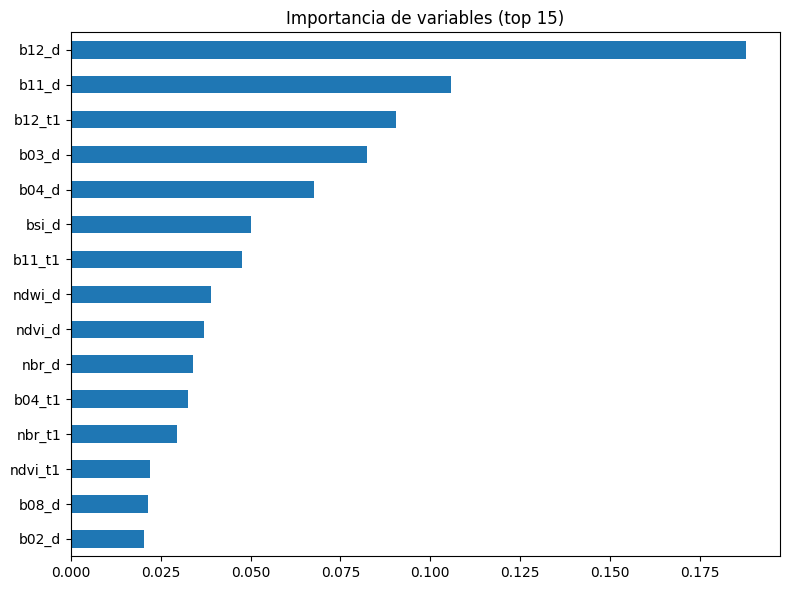

In [0]:
rf.fit(Xs, ys)
try:
    import mlflow, mlflow.sklearn
    with mlflow.start_run(run_name="rf_perdida_bosque_mdd"):
        mlflow.log_params({"n_estimators": 120, "max_depth": 14, "y0": Y0, "y1": Y1, "n_muestra": len(pdf),
                           "etiqueta": FUENTE_ETIQUETA})
        mlflow.log_metrics({"auc_aleatorio": auc_rand.mean(), "auc_bloques": auc_esp.mean()})
        mlflow.sklearn.log_model(rf, "model", input_example=pdf[FEATURES].head(3))
    print("Modelo registrado en MLflow")
except Exception as e:
    print("MLflow no disponible en este entorno:", e)

imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values().tail(15)
imp.plot.barh(figsize=(8, 6), title="Importancia de variables (top 15)")
plt.tight_layout(); plt.savefig(FIG / "06_importancia.png", dpi=150); plt.show()

### Puntuación distribuida de todos los píxeles

In [0]:
from pyspark.sql import types as T
model, feats = rf, FEATURES
out_schema = T.StructType([T.StructField("row", T.IntegerType()), T.StructField("col", T.IntegerType()),
                           T.StructField("lon", T.DoubleType()), T.StructField("lat", T.DoubleType()),
                           T.StructField("label", T.IntegerType()), T.StructField("prob", T.FloatType())])

def score(it):
    for p in it:
        prob = model.predict_proba(p[feats].fillna(0).values)[:, 1]
        yield pd.DataFrame({"row": p.row, "col": p.col, "lon": p.lon, "lat": p.lat,
                            "label": p.label, "prob": prob.astype("float32")})

pred = data.select("row", "col", "lon", "lat", "label", *FEATURES).mapInPandas(score, schema=out_schema)
dbx.save_table(pred, "gold_pred_perdida_pixel")
pred = spark.table(dbx.tbl("gold_pred_perdida_pixel"))
print(f"Píxeles puntuados: {pred.count():,}")

Píxeles puntuados: 4,726,224


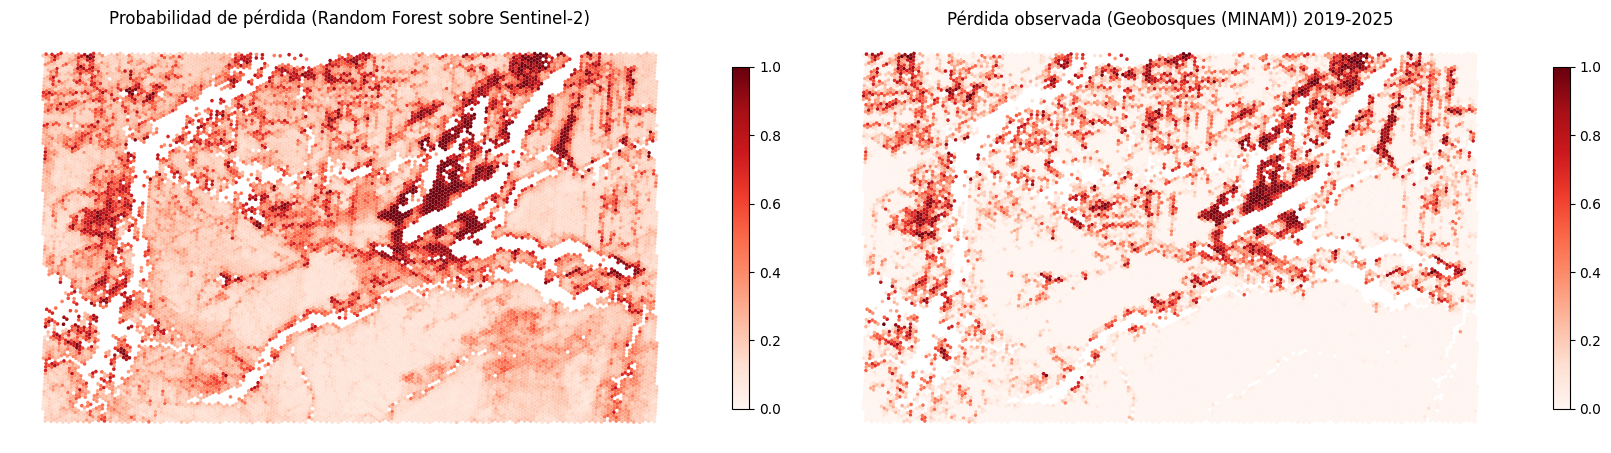

Correlación por hexágono modelo vs Geobosques (MINAM): 0.888


In [0]:
pred.createOrReplaceTempView("pred")
ph = spark.sql(f"""
SELECT h3_longlatash3string(lon, lat, {C.H3_RES_FINE}) AS h3,
       AVG(prob) AS prob_modelo, AVG(label) AS perdida_observada, COUNT(*) AS n
FROM pred GROUP BY 1 HAVING n >= 50""").toPandas().pipe(dbx.clean)
gph = spatial.h3_to_geodataframe(ph, crs_out=C.CRS_UTM)
fig, ax = plt.subplots(1, 2, figsize=(17, 6))
gph.plot(column="prob_modelo", cmap="Reds", vmin=0, vmax=1, linewidth=0, ax=ax[0], legend=True, legend_kwds={"shrink": 0.6})
ax[0].set_title("Probabilidad de pérdida (Random Forest sobre Sentinel-2)")
gph.plot(column="perdida_observada", cmap="Reds", vmin=0, vmax=1, linewidth=0, ax=ax[1], legend=True, legend_kwds={"shrink": 0.6})
ax[1].set_title(f"Pérdida observada ({FUENTE_ETIQUETA}) {Y0+1}-{Y1}")
for a in ax: a.set_axis_off()
plt.tight_layout(); plt.savefig(FIG / "06_prediccion.png", dpi=150); plt.show()
print(f"Correlación por hexágono modelo vs {FUENTE_ETIQUETA}: {ph[['prob_modelo','perdida_observada']].corr().iloc[0,1]:.3f}")

## Conclusiones técnicas

1. **Escala:** el procesamiento se expresó como operaciones sobre DataFrames (teselas → píxeles →
   hexágonos), así que el mismo código sirve para un corredor o para toda la Amazonía peruana.
2. **Estadística espacial:** la perturbación muestra autocorrelación positiva fuerte, clusters
   Bajo-Bajo de ΔNDVI y puntos calientes Gi* alineados con los ríos.
3. **Geoestadística:** el kriging aprovecha la dependencia espacial para recuperar información
   perdida por nubes, con incertidumbre cuantificada.
4. **ML:** la validación por bloques espaciales es imprescindible; la validación aleatoria
   sobreestima el desempeño.

# datos usados desde la nube

In [0]:
import os, pandas as pd

def peso_carpeta(p):
    return sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(p) for f in fs) / 1e9

vol = "/Volumes/workspace/madre_dios_rs/raw"
filas = [{"capa": "Volume/" + d, "GB": round(peso_carpeta(f"{vol}/{d}"), 3)}
         for d in sorted(os.listdir(vol)) if os.path.isdir(f"{vol}/{d}")]

for t in spark.sql("SHOW TABLES IN workspace.madre_dios_rs").collect():
    if t.isTemporary:          # vistas temporales de los notebooks: no son tablas físicas
        continue
    nombre = f"workspace.madre_dios_rs.{t.tableName}"
    det = spark.sql(f"DESCRIBE DETAIL {nombre}").first()
    filas.append({"capa": "Tabla Delta: " + t.tableName, "GB": round(det.sizeInBytes / 1e9, 3),
                  "filas": spark.table(nombre).count()})

res = pd.DataFrame(filas)
display(res)
print(f"TOTAL en la nube: {res.GB.sum():.2f} GB")

capa,GB,filas
Volume/bronze,1.427,null
Volume/figures,0.012,null
Volume/gold,0.046,null
Volume/landing,0.743,null
Tabla Delta: bronze_s2_files,0.0,869.0
Tabla Delta: bronze_s2_items,0.0,60.0
Tabla Delta: bronze_vec_areas_protegidas_sernanp,0.0,2.0
Tabla Delta: bronze_vec_distritos_madre_de_dios,0.0,10.0
Tabla Delta: bronze_vec_rios,0.0,67.0
Tabla Delta: bronze_vec_vias,0.0,70.0


TOTAL en la nube: 3.67 GB
